# **Penting**
- Pastikan Anda melakukan Run All sebelum mengirimkan submission untuk memastikan seluruh cell berjalan dengan baik.
- Pastikan Anda menggunakan variabel df dari awal sampai akhir dan tidak diperbolehkan mengganti nama variabel tersebut.
- Hapus simbol pagar (#) pada kode yang bertipe komentar jika Anda menerapkan kriteria tambahan
- Biarkan simbol pagar (#) jika Anda tidak menerapkan kriteria tambahan

# **INFORMASI DATASET**
## Latar Belakang

Dalam dunia bisnis ritel, pemahaman terhadap perilaku pelanggan menjadi salah satu faktor krusial dalam menentukan strategi pemasaran, peningkatan layanan, serta pengambilan keputusan berbasis data. Salah satu pendekatan yang umum digunakan untuk memahami perilaku pelanggan adalah melalui segmentasi, yaitu proses pengelompokan pelanggan ke dalam beberapa segmen atau kelompok berdasarkan karakteristik tertentu.

Dengan menerapkan metode **unsupervised learning**, khususnya **clustering**, proyek ini bertujuan untuk membentuk segmentasi pelanggan yang merepresentasikan pola-pola pembelian yang serupa. Hasil segmentasi ini diharapkan dapat memberikan insight yang bernilai bagi pihak manajemen, khususnya dalam menyusun strategi promosi yang lebih tepat sasaran, mengembangkan program loyalitas, serta mengoptimalkan layanan pelanggan.

# **1. Import Library**
Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning. Semua library yang dibutuhkan harus **import** di **cell** ini, jika ada library yang dijalankan di cell lain maka **submission langsung ditolak**

In [3]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib # For saving models

# Preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, LabelEncoder, StandardScaler
from sklearn.decomposition import PCA

# Clustering
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from yellowbrick.cluster import KElbowVisualizer

# Classification
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier # Adding more classifiers
from sklearn.linear_model import LogisticRegression # Adding more classifiers
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Set style for plots
sns.set_style("whitegrid")

# **2. Memuat Dataset**
Pada tahap ini, Anda perlu memuat dataset ke dalam notebook lalu mengecek informasi dataset sebelum nantinya dilakukan pembersihan. Hal-hal yang perlu dilakukan pada tahapan ini yaitu:
1. **Memahami Struktur Data**
   - Dataset harus mengambil referensi wajib digunakan (bisa dilihat [Disini](https://drive.google.com/drive/folders/1Zs7VmPZ-jNwsRlMKH65Ea-LApSwx6lKx?usp=drive_link))
   - Melakukan loading dataset ke dalam notebook dan menampilkan 5 baris pertama dengan function `head`.
   - Tinjau jumlah baris kolom dan jenis data dalam dataset dengan function `info`.  
   - Menampilkan statistik deskriptif dataset dengan menjalankan `describe`.
   - Pastikan **setiap function tersebut** memiliki **output pada setiap cell** code. Jika tidak **submission langsung ditolak**
   

Gunakan code ini untuk melakukan load data secara otomatis tanpa harus download data tersebut secara manual:
```python
url='https://drive.google.com/uc?id=1gnLO9qvEPqv1uBt1928AcsCmdvzqjC5m'
df = pd.read_csv(url)
```

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
 df = pd.read_csv('/content/drive/MyDrive/Dataset/bank_transactions_data_edited.csv')

In [6]:
# Tampilkan 5 baris pertama dengan function head.
df.head(5)

,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70.0,Doctor,81.0,1.0,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68.0,Doctor,141.0,1.0,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19.0,Student,56.0,1.0,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26.0,Student,25.0,1.0,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,NaN,Student,198.0,1.0,7429.40,2024-11-04 08:06:39


In [7]:
# Tinjau jumlah baris kolom dan jenis data dalam dataset dengan info.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2537 entries, 0 to 2536
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2508 non-null   object 
 1   AccountID                2516 non-null   object 
 2   TransactionAmount        2511 non-null   float64
 3   TransactionDate          2509 non-null   object 
 4   TransactionType          2507 non-null   object 
 5   Location                 2507 non-null   object 
 6   DeviceID                 2507 non-null   object 
 7   IP Address               2517 non-null   object 
 8   MerchantID               2514 non-null   object 
 9   Channel                  2510 non-null   object 
 10  CustomerAge              2519 non-null   float64
 11  CustomerOccupation       2514 non-null   object 
 12  TransactionDuration      2511 non-null   float64
 13  LoginAttempts            2516 non-null   float64
 14  AccountBalance          

In [8]:
# Menampilkan statistik deskriptif dataset dengan menjalankan describe
df.describe()

,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance
count,2511.000000,2519.000000,2511.000000,2516.000000,2510.000000
mean,297.656468,44.678444,119.422939,1.121622,5113.438124
std,292.230367,17.837359,70.078513,0.594469,3897.975861
min,0.260000,18.000000,10.000000,1.000000,101.250000
25%,81.310000,27.000000,63.000000,1.000000,1504.727500
50%,211.360000,45.000000,112.000000,1.000000,4734.110000
75%,413.105000,59.000000,161.000000,1.000000,7672.687500
max,1919.110000,80.000000,300.000000,5.000000,14977.990000


(Opsional) Memuat Dataset dan Melakukan Exploratory Data Analysis (EDA) [Skilled]

**Biarkan kosong jika tidak menerapkan kriteria skilled**

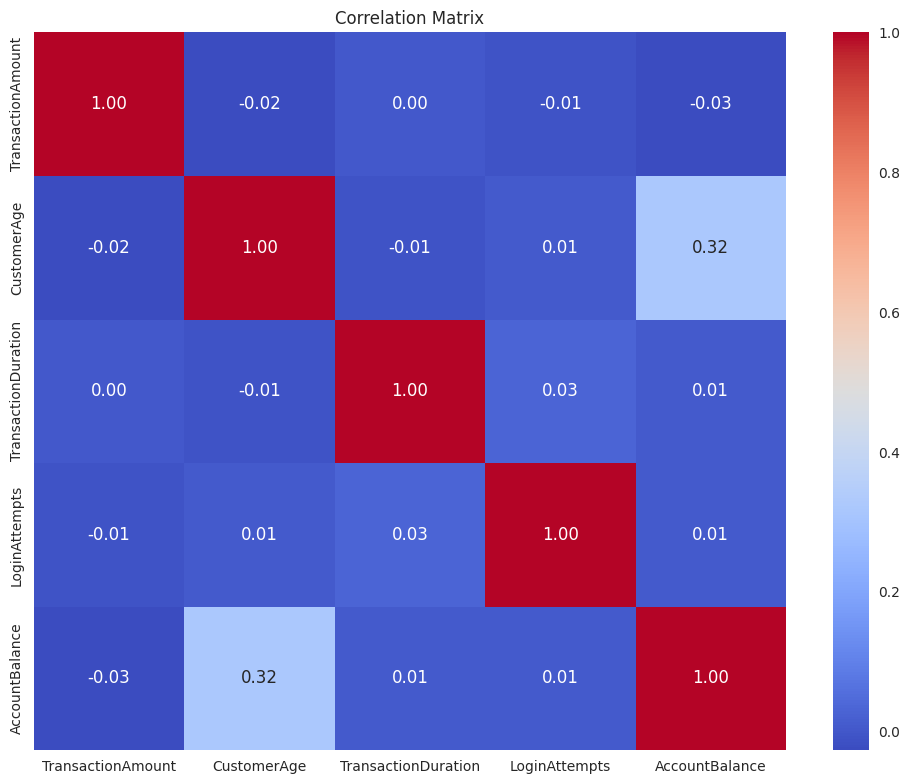

In [9]:
# Menampilkan korelasi antar fitur (Opsional Skilled 1)
df_numeric = df.select_dtypes(include=np.number)
plt.figure(figsize=(10, 8))
sns.heatmap(df_numeric.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.tight_layout() # Menyesuaikan layout agar label tidak tumpang tindih
plt.show()

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

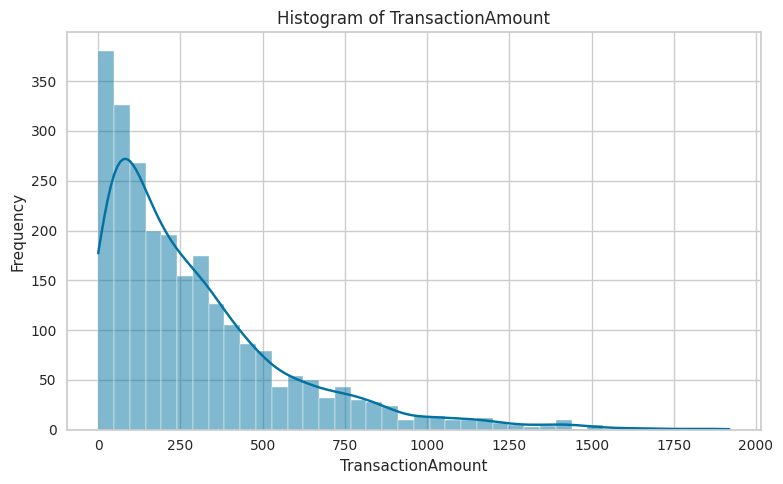

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

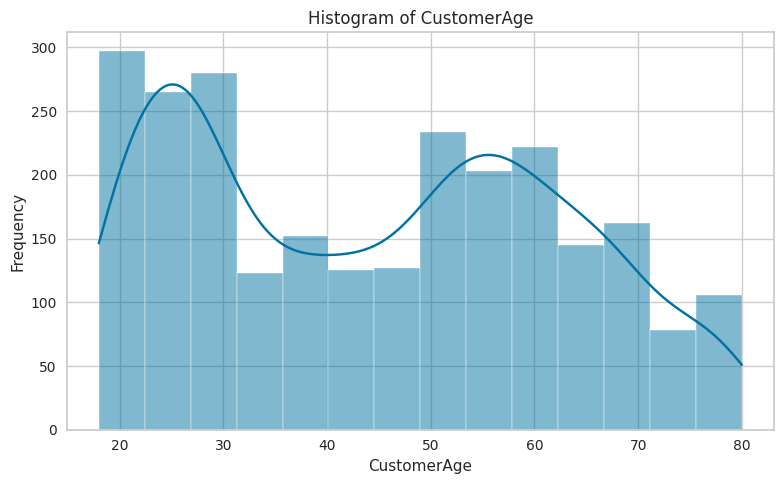

<Figure size 800x500 with 0 Axes>

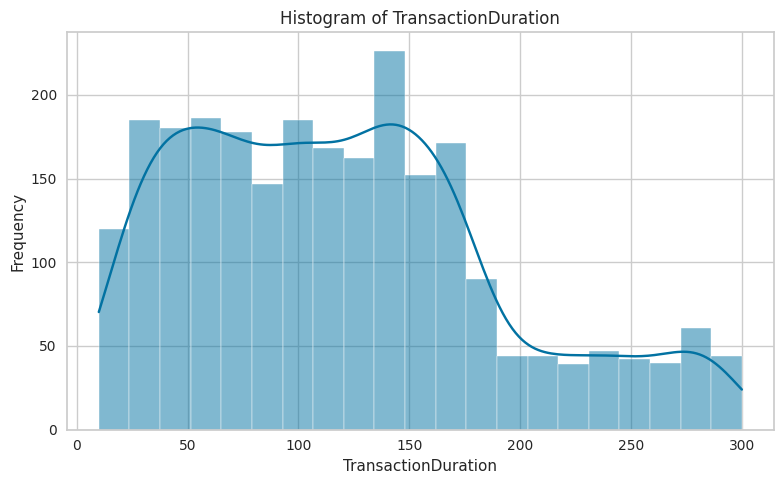

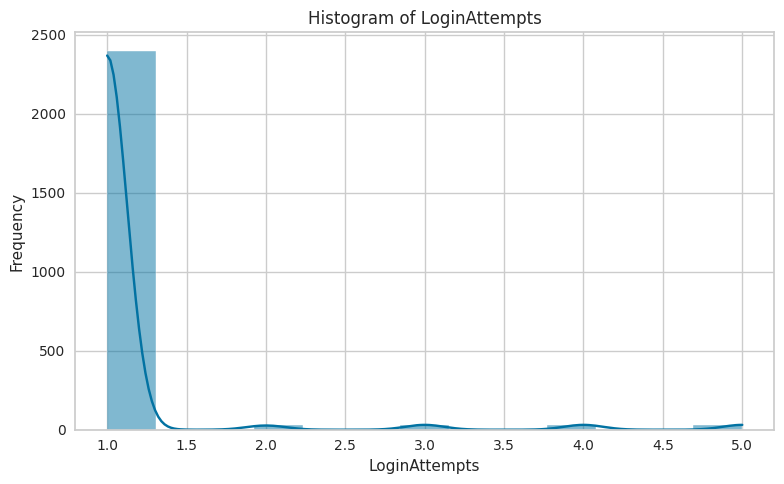

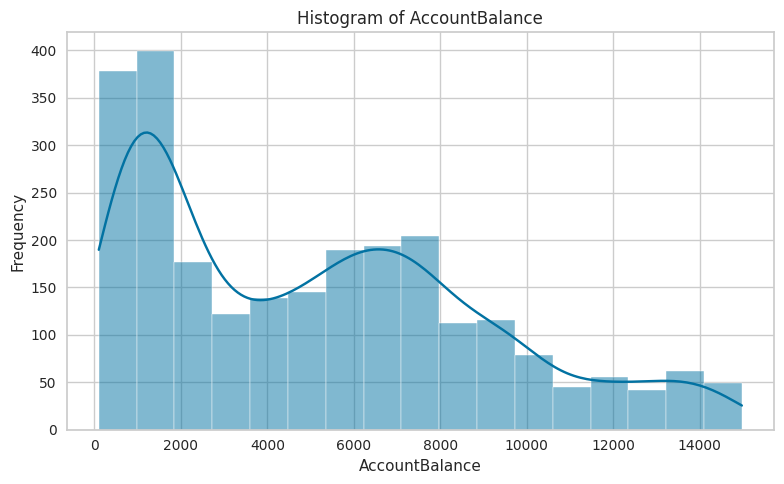

<Figure size 800x500 with 0 Axes>

In [10]:
# Menampilkan histogram untuk semua kolom numerik (Opsional Skilled 1)

for col in df.columns:
    plt.figure(figsize=(8, 5))
    if df[col].dtype in ['int64', 'float64']:
        # Check for too many unique values in numeric, might indicate IDs not dropped or other issues
        if df[col].nunique() > 50 and df[col].nunique() != df.shape[0]:
             print(f"Warning: Column '{col}' is numeric but has many unique values ({df[col].nunique()}). Displaying histogram.")
        sns.histplot(df[col].dropna(), kde=True) # Use histplot for numeric, handle NaNs
        plt.title(f'Histogram of {col}')
        plt.xlabel(col)
        plt.ylabel('Frequency')
        plt.tight_layout()
        plt.show()

(Opsional) Memuat Dataset dan Melakukan Exploratory Data Analysis (EDA) [Advanced]

**Biarkan kosong jika tidak menerapkan kriteria advanced**

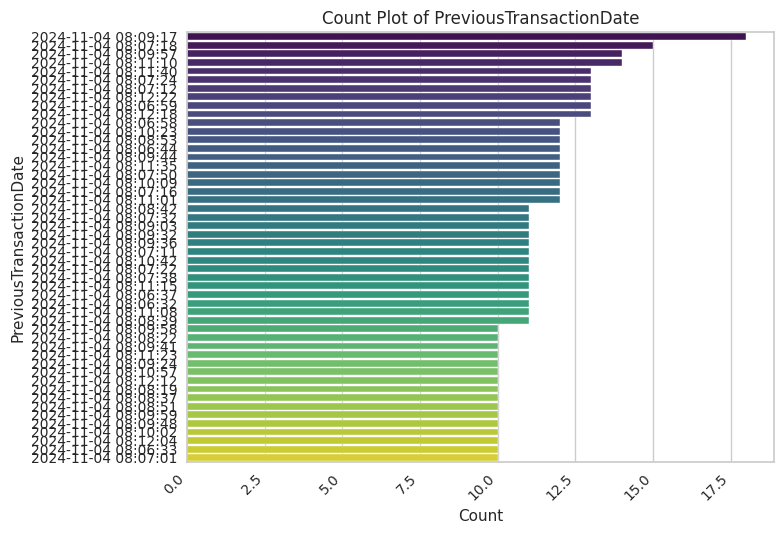

In [11]:
# Visualisasi yang lebih informatif (Opsional Advanced 1)
value_counts = df[col].value_counts()
if len(value_counts) > 50: # Limit if too many categories for countplot readability
  print(f"Warning: Column '{col}' has too many unique values ({len(value_counts)}). Showing top 50 counts.")
  value_counts = value_counts.head(50)
  sns.countplot(y=col, data=df, order=value_counts.index, palette='viridis') # Use countplot for categorical, added palette
  plt.title(f'Count Plot of {col}')
  plt.xlabel('Count')
  plt.ylabel(col)
  plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
  plt.tight_layout() # Menyesuaikan layout agar label tidak tumpang tindih
  plt.show()

# **3. Pembersihan dan Pra Pemrosesan Data**

Pada tahap ini, Anda akan melakukan **Pembersihan Dataset** untuk menjadikan dataset mudah diintepretasi dan bisa dilatih. Hal-hal yang wajib kamu lakukan yaitu:

1. **Mengecek dataset** menggunakan isnull().sum() dan duplicated().sum().
2. Melakukan feature scaling menggunakan `MinMaxScaler()` atau `StandardScalar()` untuk fitur numerik.
3. Melakukan feature encoding menggunakan `LabelEncoder()` untuk fitur kategorikal.
4. Melakukan drop pada kolom id.
5. **Ketentuan Cell Code**
   - Pastikan **setiap pemeriksaan tersebut** memiliki **output pada cell-nya**. Jika tidak **submission langsung ditolak**


In [12]:
# Mengecek dataset menggunakan isnull().sum()
print(df.isnull().sum())

TransactionID              29
AccountID                  21
TransactionAmount          26
TransactionDate            28
TransactionType            30
Location                   30
DeviceID                   30
IP Address                 20
MerchantID                 23
Channel                    27
CustomerAge                18
CustomerOccupation         23
TransactionDuration        26
LoginAttempts              21
AccountBalance             27
PreviousTransactionDate    24
dtype: int64


In [13]:
# Mengecek dataset menggunakan duplicated().sum()
print(df.duplicated().sum())

21


In [14]:
# Melakukan feature scaling menggunakan MinMaxScaler() atau StandardScalar() untuk fitur numerik.
# Separate features by type for easier processing,
df_numeric = df.select_dtypes(include=np.number)
df_categorical = df.select_dtypes(exclude=np.number)

# Handle Missing Data (Imputation),
# Use median for numeric to be less sensitive to outliers, mode for categorical,
numeric_imputer = SimpleImputer(strategy='median')
categorical_imputer = SimpleImputer(strategy='most_frequent')

df_numeric_imputed = pd.DataFrame(numeric_imputer.fit_transform(df_numeric), columns=df_numeric.columns)
df_categorical_imputed = pd.DataFrame(categorical_imputer.fit_transform(df_categorical), columns=df_categorical.columns)

print(f"\nMissing values after imputation (numeric): {df_numeric_imputed.isnull().sum().sum()}")
print(f"Missing values after imputation (categorical): {df_categorical_imputed.isnull().sum().sum()}")

# Handle Outlier using capping (IQR method),
print("\nHandling Outliers (Capping using IQR)...")
for col in df_numeric_imputed.columns:
    # Only apply capping if the column is not constant after imputation
    if df_numeric_imputed[col].nunique() > 1:
        Q1 = df_numeric_imputed[col].quantile(0.25)
        Q3 = df_numeric_imputed[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Apply capping
        df_numeric_imputed[col] = np.where(df_numeric_imputed[col] < lower_bound, lower_bound, df_numeric_imputed[col])
        df_numeric_imputed[col] = np.where(df_numeric_imputed[col] > upper_bound, upper_bound, df_numeric_imputed[col])
        print(f" Outlier capping applied to '{col}'.")
    else:
        print(f" Outlier capping skipped for '{col}' (constant values).")
print("Outlier handling complete.")
# Melakukan binning data,
# Select one or two numeric features for binning. Let's choose TransactionAmount and possibly CustomerAge (if it exists),
numeric_cols_for_binning = []
if 'TransactionAmount' in df_numeric_imputed.columns:
    numeric_cols_for_binning.append('TransactionAmount')
if 'CustomerAge' in df_numeric_imputed.columns: # Assuming 'CustomerAge' might exist
     numeric_cols_for_binning.append('CustomerAge')

binned_features_df = pd.DataFrame()

for col in numeric_cols_for_binning:
    if col in df_numeric_imputed.columns and df_numeric_imputed[col].nunique() > 4: # Ensure enough unique values for 4 bins
        print(f"Applying binning to '{col}'...")
        try:
            # Use pd.qcut to create quantile-based bins, handles uneven distributions better
            # Create 4 quantile bins
            # Handle potential duplicates in quantiles for qcut
            df_numeric_imputed[f'{col}_Bin'] = pd.qcut(df_numeric_imputed[col], q=4, labels=False, duplicates='drop')
            print(f"Created '{col}_Bin'.")
            # Encode the binned column using get_dummies
            binned_dummies = pd.get_dummies(df_numeric_imputed[f'{col}_Bin'], prefix=f'{col}_Bin', drop_first=True)
            binned_features_df = pd.concat([binned_features_df, binned_dummies], axis=1)
            print(f"Encoded '{col}_Bin' using get_dummies.")
            # Drop the original binned column after encoding
            df_numeric_imputed.drop(columns=[f'{col}_Bin'], inplace=True)
        except Exception as e:
            print(f"Could not apply binning to '{col}': {e}")
    else:
         print(f"Skipping binning for '{col}' due to insufficient unique values.")
# Melakukan feature scaling menggunakan MinMaxScaler() untuk fitur numerik,
# Exclude binary columns that resulted from binning if they somehow ended up here before scaling,
numeric_cols_to_scale = df_numeric_imputed.columns.difference(binned_features_df.columns)
scaler = MinMaxScaler()
df_numeric_scaled = pd.DataFrame(scaler.fit_transform(df_numeric_imputed[numeric_cols_to_scale]), columns=numeric_cols_to_scale)
print("\nNumeric features scaled using MinMaxScaler.")
# Pastikan kamu menggunakan function head setelah melalukan scaling.
df_processed = df_numeric_scaled.join(binned_features_df)
df_processed.head()


Missing values after imputation (numeric): 0
Missing values after imputation (categorical): 0

Handling Outliers (Capping using IQR)...
 Outlier capping applied to 'TransactionAmount'.
 Outlier capping applied to 'CustomerAge'.
 Outlier capping applied to 'TransactionDuration'.
 Outlier capping applied to 'LoginAttempts'.
 Outlier capping applied to 'AccountBalance'.
Outlier handling complete.
Applying binning to 'TransactionAmount'...
Created 'TransactionAmount_Bin'.
Encoded 'TransactionAmount_Bin' using get_dummies.
Applying binning to 'CustomerAge'...
Created 'CustomerAge_Bin'.
Encoded 'CustomerAge_Bin' using get_dummies.

Numeric features scaled using MinMaxScaler.


,AccountBalance,CustomerAge,LoginAttempts,TransactionAmount,TransactionDuration,TransactionAmount_Bin_1,TransactionAmount_Bin_2,TransactionAmount_Bin_3,CustomerAge_Bin_1,CustomerAge_Bin_2,CustomerAge_Bin_3
0,0.336832,0.838710,0.0,0.015381,0.244828,False,False,False,False,False,True
1,0.918055,0.806452,0.0,0.418146,0.451724,False,True,False,False,False,True
2,0.068637,0.016129,0.0,0.140164,0.158621,True,False,False,False,False,False
3,0.569198,0.129032,0.0,0.204902,0.051724,True,False,False,False,False,False
4,0.492591,0.435484,0.0,0.014669,0.648276,False,False,False,True,False,False


In [15]:
# Melakukan drop pada kolom yang memiliki keterangan id dan IP Address
# Menghapus data duplikat menggunakan drop_duplicates()
initial_rows = df.shape[0]
df.drop_duplicates(inplace=True)
rows_after_duplicates = df.shape[0]
print(f"\nDropped {initial_rows - rows_after_duplicates} duplicate rows.")
print(f"Remaining rows: {rows_after_duplicates}")

# Melakukan drop pada kolom yang memiliki keterangan ID
id_columns_to_drop = ['TransactionID', 'AccountID', 'DeviceID', 'IPAddress', 'MerchantID']
# Check which columns actually exist before dropping
existing_id_columns = [col for col in id_columns_to_drop if col in df.columns]
df.drop(columns=existing_id_columns, inplace=True)
print(f"\nDropped ID columns: {existing_id_columns}")
print("Remaining columns:", df.columns.tolist())


Dropped 21 duplicate rows.
Remaining rows: 2516

Dropped ID columns: ['TransactionID', 'AccountID', 'DeviceID', 'MerchantID']
Remaining columns: ['TransactionAmount', 'TransactionDate', 'TransactionType', 'Location', 'IP Address', 'Channel', 'CustomerAge', 'CustomerOccupation', 'TransactionDuration', 'LoginAttempts', 'AccountBalance', 'PreviousTransactionDate']


In [16]:
# Melakukan feature encoding menggunakan LabelEncoder() untuk fitur kategorikal.
original_categorical_columns = df_categorical_imputed.columns.tolist()
df_categorical_encoded = pd.get_dummies(df_categorical_imputed, drop_first=True)
print(f"Categorical features encoded using pd.get_dummies. Original columns: {original_categorical_columns}")

# Pastikan kamu menggunakan function head setelah melalukan encoding.
df_processed = df_numeric_scaled.join(df_categorical_encoded)
df_processed.head()


Categorical features encoded using pd.get_dummies. Original columns: ['TransactionID', 'AccountID', 'TransactionDate', 'TransactionType', 'Location', 'DeviceID', 'IP Address', 'MerchantID', 'Channel', 'CustomerOccupation', 'PreviousTransactionDate']


,AccountBalance,CustomerAge,LoginAttempts,TransactionAmount,TransactionDuration,TransactionID_TX000002,TransactionID_TX000003,TransactionID_TX000004,TransactionID_TX000005,TransactionID_TX000006,...,PreviousTransactionDate_2024-11-04 08:12:14,PreviousTransactionDate_2024-11-04 08:12:15,PreviousTransactionDate_2024-11-04 08:12:16,PreviousTransactionDate_2024-11-04 08:12:17,PreviousTransactionDate_2024-11-04 08:12:18,PreviousTransactionDate_2024-11-04 08:12:19,PreviousTransactionDate_2024-11-04 08:12:20,PreviousTransactionDate_2024-11-04 08:12:21,PreviousTransactionDate_2024-11-04 08:12:22,PreviousTransactionDate_2024-11-04 08:12:23
0,0.336832,0.838710,0.0,0.015381,0.244828,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,0.918055,0.806452,0.0,0.418146,0.451724,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,0.068637,0.016129,0.0,0.140164,0.158621,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,0.569198,0.129032,0.0,0.204902,0.051724,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
4,0.492591,0.435484,0.0,0.014669,0.648276,False,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False


In [17]:
# Last checking gunakan columns.tolist() untuk checking seluruh fitur yang ada.
# Perbaiki kode di bawah ini tanpa menambahkan atau mengurangi cell code ini.
columns = df_processed.columns
columns.tolist()

['AccountBalance',
 'CustomerAge',
 'LoginAttempts',
 'TransactionAmount',
 'TransactionDuration',
 'TransactionID_TX000002',
 'TransactionID_TX000003',
 'TransactionID_TX000004',
 'TransactionID_TX000005',
 'TransactionID_TX000006',
 'TransactionID_TX000007',
 'TransactionID_TX000008',
 'TransactionID_TX000009',
 'TransactionID_TX000010',
 'TransactionID_TX000011',
 'TransactionID_TX000012',
 'TransactionID_TX000013',
 'TransactionID_TX000014',
 'TransactionID_TX000015',
 'TransactionID_TX000016',
 'TransactionID_TX000017',
 'TransactionID_TX000018',
 'TransactionID_TX000019',
 'TransactionID_TX000020',
 'TransactionID_TX000021',
 'TransactionID_TX000022',
 'TransactionID_TX000023',
 'TransactionID_TX000024',
 'TransactionID_TX000025',
 'TransactionID_TX000026',
 'TransactionID_TX000027',
 'TransactionID_TX000028',
 'TransactionID_TX000029',
 'TransactionID_TX000030',
 'TransactionID_TX000031',
 'TransactionID_TX000032',
 'TransactionID_TX000033',
 'TransactionID_TX000034',
 'Transact

(Opsional) Pembersihan dan Pra Pemrosesan Data [Skilled]

**Biarkan kosong jika tidak menerapkan kriteria skilled**

In [18]:
# Menangani data yang hilang (bisa menggunakan dropna() atau metode imputasi fillna()).


In [19]:
# Menghapus data duplikat menggunakan drop_duplicates().

(Opsional) Pembersihan dan Pra Pemrosesan Data [Advanced]

**Biarkan kosong jika tidak menerapkan kriteria advanced**

In [20]:
# Melakukan Handling Outlier Data berdasarkan jumlah outlier, apakah menggunakan metode drop atau mengisi nilai tersebut.
# Handle Outlier using capping (IQR method)
print("\nHandling Outliers (Capping using IQR)...")
for col in df_numeric_imputed.columns:
    # Only apply capping if the column is not constant after imputation
    if df_numeric_imputed[col].nunique() > 1:
        Q1 = df_numeric_imputed[col].quantile(0.25)
        Q3 = df_numeric_imputed[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Apply capping
        df_numeric_imputed[col] = np.where(df_numeric_imputed[col] < lower_bound, lower_bound, df_numeric_imputed[col])
        df_numeric_imputed[col] = np.where(df_numeric_imputed[col] > upper_bound, upper_bound, df_numeric_imputed[col])
        print(f" Outlier capping applied to '{col}'.")
    else:
        print(f" Outlier capping skipped for '{col}' (constant values).")
print("Outlier handling complete.")


Handling Outliers (Capping using IQR)...
 Outlier capping applied to 'TransactionAmount'.
 Outlier capping applied to 'CustomerAge'.
 Outlier capping applied to 'TransactionDuration'.
 Outlier capping skipped for 'LoginAttempts' (constant values).
 Outlier capping applied to 'AccountBalance'.
Outlier handling complete.


In [21]:
# Melakukan binning data berdasarkan kondisi rentang nilai pada fitur numerik,
# Select one or two numeric features for binning. Let's choose TransactionAmount and possibly CustomerAge (if it exists)
numeric_cols_for_binning = []
if 'TransactionAmount' in df_numeric_imputed.columns:
    numeric_cols_for_binning.append('TransactionAmount')
if 'CustomerAge' in df_numeric_imputed.columns: # Assuming 'CustomerAge' might exist
     numeric_cols_for_binning.append('CustomerAge')

binned_features_df = pd.DataFrame()

for col in numeric_cols_for_binning:
    if col in df_numeric_imputed.columns and df_numeric_imputed[col].nunique() > 4: # Ensure enough unique values for 4 bins
        print(f"Applying binning to '{col}'...")
        try:
            # Use pd.qcut to create quantile-based bins, handles uneven distributions better
            # Create 4 quantile bins
            # Handle potential duplicates in quantiles for qcut
            df_numeric_imputed[f'{col}_Bin'] = pd.qcut(df_numeric_imputed[col], q=4, labels=False, duplicates='drop')
            print(f"Created '{col}_Bin'.")
            # Encode the binned column using get_dummies
            binned_dummies = pd.get_dummies(df_numeric_imputed[f'{col}_Bin'], prefix=f'{col}_Bin', drop_first=True)
            binned_features_df = pd.concat([binned_features_df, binned_dummies], axis=1)
            print(f"Encoded '{col}_Bin' using get_dummies.")
            # Drop the original binned column after encoding
            df_numeric_imputed.drop(columns=[f'{col}_Bin'], inplace=True)
        except Exception as e:
            print(f"Could not apply binning to '{col}': {e}")
    else:
         print(f"Skipping binning for '{col}' due to insufficient unique values.")
# lakukan pada satu sampai dua fitur numerik.
# Melakukan feature scaling menggunakan MinMaxScaler() untuk fitur numerik
# Exclude binary columns that resulted from binning if they somehow ended up here before scaling
numeric_cols_to_scale = df_numeric_imputed.columns.difference(binned_features_df.columns)
scaler = MinMaxScaler()
df_numeric_scaled = pd.DataFrame(scaler.fit_transform(df_numeric_imputed[numeric_cols_to_scale]), columns=numeric_cols_to_scale)
print("\nNumeric features scaled using MinMaxScaler.")

# Silahkan lakukan encode hasil binning tersebut menggunakan LabelEncoder.
# Melakukan feature encoding menggunakan pd.get_dummies() untuk fitur kategorikal
# Store original categorical columns for inverse transformation later
original_categorical_columns = df_categorical_imputed.columns.tolist()
df_categorical_encoded = pd.get_dummies(df_categorical_imputed, drop_first=True)
print(f"Categorical features encoded using pd.get_dummies. Original columns: {original_categorical_columns}")


Applying binning to 'TransactionAmount'...
Created 'TransactionAmount_Bin'.
Encoded 'TransactionAmount_Bin' using get_dummies.
Applying binning to 'CustomerAge'...
Created 'CustomerAge_Bin'.
Encoded 'CustomerAge_Bin' using get_dummies.

Numeric features scaled using MinMaxScaler.
Categorical features encoded using pd.get_dummies. Original columns: ['TransactionID', 'AccountID', 'TransactionDate', 'TransactionType', 'Location', 'DeviceID', 'IP Address', 'MerchantID', 'Channel', 'CustomerOccupation', 'PreviousTransactionDate']


# **4. Membangun Model Clustering**
Pada tahap ini, Anda membangun model clustering dengan memilih algoritma yang sesuai untuk mengelompokkan data berdasarkan kesamaan.
1. Pastikan Anda menggunakan dataframe yang sudah melalui processing sesuai dengan levelnya (Basic, Skilled, Advanced)
2. Melakukan visualisasi Elbow Method untuk menentukan jumlah cluster terbaik menggunakan `KElbowVisualizer()`.
3. Menggunakan algoritma K-Means Clustering dengan `sklearn.cluster.KMeans()`.
4. Jalankan cell code `joblib.dump(model_kmeans, "best_model_clustering.h5")` untuk menyimpan model yang sudah dibuat.

In [22]:
# Gunakan describe untuk memastikan proses clustering menggunakan dataset hasil preprocessing
X_clustering = df_processed.copy()
# Lengkapi kode ini dengan mengubah nama DataFrame yang akan dilatih.
dfX_clustering = pd.DataFrame(X_clustering)
# Kode harus digunakan dan dilarang menambahkan syntax lainnya pada cell ini.
dfX_clustering.describe()

,AccountBalance,CustomerAge,LoginAttempts,TransactionAmount,TransactionDuration
count,2537.000000,2537.000000,2537.0,2537.000000,2537.000000
mean,0.336643,0.430334,0.0,0.315010,0.377058
std,0.260633,0.286677,0.0,0.277573,0.240422
min,0.000000,0.000000,0.0,0.000000,0.000000
25%,0.095323,0.145161,0.0,0.092097,0.182759
50%,0.311416,0.435484,0.0,0.234775,0.351724
75%,0.505876,0.661290,0.0,0.455258,0.520690
max,1.000000,1.000000,0.0,1.000000,1.000000



Applied PCA. Original dimensions: 7242, Reduced dimensions: 2
Explained variance ratio by components: 0.0708

Performing Elbow Method to find optimal number of clusters...


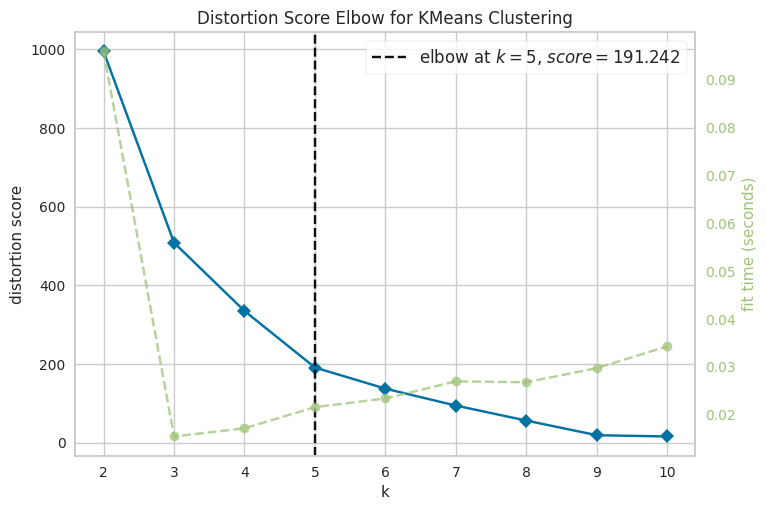


Optimal number of clusters chosen based on Elbow Method: 4


In [23]:
# Melakukan visualisasi Elbow Method menggunakan KElbowVisualizer()
# Let's choose n_components to explain 95% variance or a fixed number like 2 for visualization
pca = PCA(n_components=0.95, random_state=42) # Explain 95% variance
pca = PCA(n_components=2, random_state=42) # For easier visualization - uncomment if preferred
X_pca = pca.fit_transform(X_clustering)
print(f"\nApplied PCA. Original dimensions: {X_clustering.shape[1]}, Reduced dimensions: {X_pca.shape[1]}")
print(f"Explained variance ratio by components: {pca.explained_variance_ratio_.sum():.4f}")

# Melakukan visualisasi Elbow Method untuk menentukan jumlah cluster terbaik menggunakan KElbowVisualizer()
print("\nPerforming Elbow Method to find optimal number of clusters...")
# Use the PCA transformed data for elbow method
model = KMeans(random_state=42, n_init=10) # Added n_init explicitly
visualizer = KElbowVisualizer(model, k=(2,11)) # Test k from 2 to 10

visualizer.fit(X_pca) # Fit the data to the visualizer
visualizer.show() # Finalize and render the figure

# Based on the elbow plot, choose the optimal number of clusters
# You will need to visually inspect the plot and determine the elbow point.
# For demonstration, let's assume the elbow is at k=4 (adjust based on your plot)
optimal_clusters = 4 # ADJUST THIS BASED ON YOUR ELBOW PLOT

print(f"\nOptimal number of clusters chosen based on Elbow Method: {optimal_clusters}")

In [24]:
# Menggunakan algoritma K-Means Clustering
kmeans_model = KMeans(n_clusters=optimal_clusters, random_state=42, n_init=10)
cluster_labels = kmeans_model.fit_predict(X_pca)
print(f"K-Means clustering performed with {optimal_clusters} clusters.")


K-Means clustering performed with 4 clusters.


Jalankan cell code ini untuk menyimpan model kamu.

In [35]:
# Menyimpan model menggunakan joblib
joblib.dump(pca, "PCA_model_clustering.h5")
print("PCA model saved as PCA_model_clustering.h5")
joblib.dump(kmeans_model, "model_clustering.h5")
print("K-Means model saved as model_clustering.h5")

PCA model saved as PCA_model_clustering.h5
K-Means model saved as model_clustering.h5


(Opsional) Membangun Model Clustering [Skilled]

**Biarkan kosong jika tidak menerapkan kriteria skilled**

In [26]:
# Menghitung dan menampilkan nilai Silhouette Score.
# Silhouette score requires at least 2 clusters and can be slow on large datasets
if optimal_clusters > 1:
    silhouette_avg = silhouette_score(X_pca, cluster_labels)
    print(f"\nSilhouette Score: {silhouette_avg:.4f}")
else:
    print("\nSilhouette Score not calculated as optimal clusters is 1.")


Silhouette Score: 0.5862



Visualizing Clustering Results (using first 2 PCA components)...


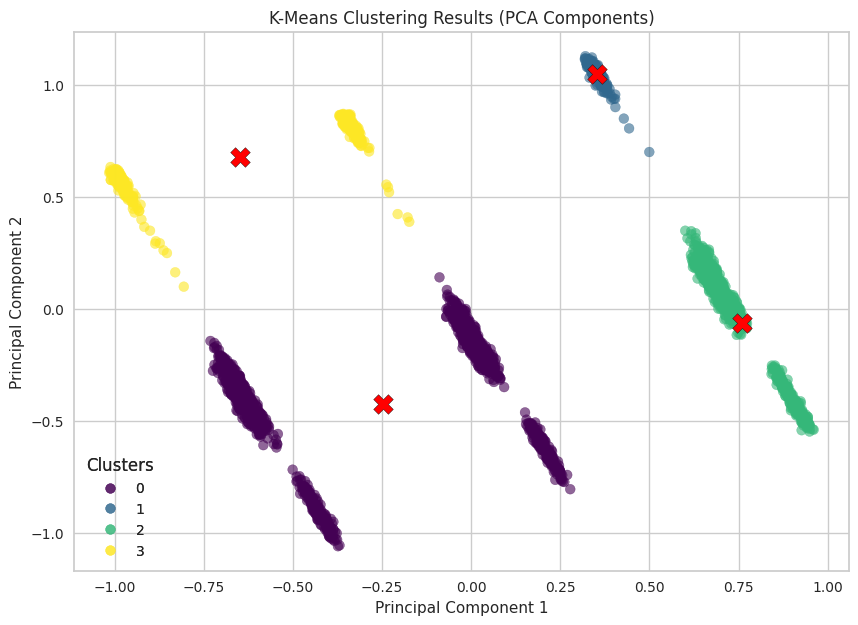

In [27]:
# Membuat visualisasi hasil clustering
# Ensure PCA resulted in at least 2 components before attempting 2D visualization
if X_pca.shape[1] >= 2:
    print("\nVisualizing Clustering Results (using first 2 PCA components)...")
    plt.figure(figsize=(10, 7))
    scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='viridis', s=50, alpha=0.6)
    plt.title('K-Means Clustering Results (PCA Components)')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    # Add centroids if PCA had only 2 components for exact match with centroid dimensions
    if X_pca.shape[1] == 2:
         # Inverse transform centroids if needed to plot on original feature scale -
         # but typically centroids are shown in the space where clustering was done (PCA space here)
         centroids = kmeans_model.cluster_centers_
         plt.scatter(centroids[:, 0], centroids[:, 1], marker='X', s=200, c='red', label='Centroids', edgecolor='k') # Added edge color
         plt.legend()
    # Create a legend for clusters
    # Handles cases where only 1 cluster is found after dropping duplicates/imputing constant columns etc.
    unique_cluster_labels = np.unique(cluster_labels)
    if len(unique_cluster_labels) > 1:
        legend1 = plt.legend(*scatter.legend_elements(), loc="lower left", title="Clusters")
        plt.gca().add_artist(legend1)

    plt.show()
else:
    print("\nCannot visualize clustering with scatter plot as PCA components are less than 2.")

(Opsional) Membangun Model Clustering [Advanced]

**Biarkan kosong jika tidak menerapkan kriteria advanced**

In [28]:
# Membangun model menggunakan PCA.
# Let's choose n_components to explain 95% variance or a fixed number like 2 for visualization
pca = PCA(n_components=0.95, random_state=42) # Explain 95% variance
pca = PCA(n_components=2, random_state=42) # For easier visualization - uncomment if preferred
X_pca = pca.fit_transform(X_clustering)
print(f"\nApplied PCA. Original dimensions: {X_clustering.shape[1]}, Reduced dimensions: {X_pca.shape[1]}")
print(f"Explained variance ratio by components: {pca.explained_variance_ratio_.sum():.4f}")


Applied PCA. Original dimensions: 7242, Reduced dimensions: 2
Explained variance ratio by components: 0.0708


In [29]:
# Simpan model PCA sebagai perbandingan dengan menjalankan cell code ini joblib.dump(model,"PCA_model_clustering.h5")
joblib.dump(pca, "PCA_model_clustering.h5")
print("PCA model saved as PCA_model_clustering.h5")

PCA model saved as PCA_model_clustering.h5


# **5. Interpretasi Cluster**

## **a. Interpretasi Hasil Clustering**
1. **Contoh Interpretasi:**
- **Cluster 1: (Nasabah Bertransaksi dan Pendapatan Besar)**:
  - **Rata-rata (mean) Annual Income:** 0.953 (48,260)
  - **Rata-rata (mean) Spending Score:** 0.8 (56.48)
  - **Analisis:** Cluster ini mencakup pelanggan dengan pendapatan tahunan tinggi dan tingkat pengeluaran yang cukup tinggi. Pelanggan dalam cluster ini cenderung memiliki daya beli yang tinggi dan mereka lebih cenderung untuk membelanjakan sebagian besar pendapatan mereka. Sehingga rekomendasi pada kelompok nasabah ini adalah dengan menawarkan produk-produk investasi atau perbankan yang berkualitas tinggi.


In [30]:
# Menampilkan analisis deskriptif minimal mean, min dan max untuk fitur numerik.
# Silakan menambahkan fungsi agregasi lainnya untuk experience lebih baik.
df_clustered_preprocessed = df_processed.copy()
df_clustered_preprocessed['Target'] = cluster_labels

df_numeric_original_structure = df_numeric_imputed[numeric_cols_to_scale].copy() # Use cols before binning
df_categorical_original_structure = df_categorical_imputed.copy()

df_numeric_inverse_scaled = pd.DataFrame(scaler.inverse_transform(df_clustered_preprocessed[numeric_cols_to_scale]),
                                         columns=numeric_cols_to_scale)
print("\nInverse transformed numeric features.")

df_categorical_inverse_encoded = pd.DataFrame(index=df_clustered_preprocessed.index)

for col in original_categorical_columns:
    dummy_cols = [d_col for d_col in df_categorical_encoded.columns if d_col.startswith(f'{col}_')]

    if dummy_cols:
        original_categories_present = df_categorical_imputed[col].dropna().unique().tolist()

        categories_from_dummies = [d_col.replace(f'{col}_', '') for d_col in dummy_cols]
        dropped_category = None
        for cat in original_categories_present:
            if cat not in categories_from_dummies:
                dropped_category = cat
                break

        all_categories = [dropped_category] + categories_from_dummies if dropped_category is not None else categories_from_dummies

        if not all_categories:
             print(f"Warning: Could not determine categories for original column '{col}'.")

             if col in df_categorical_imputed.columns and not df_categorical_imputed[col].empty:
                  df_categorical_inverse_encoded[col] = df_categorical_imputed[col].mode()[0]
             continue

        temp_dummies = df_clustered_preprocessed[dummy_cols]

        original_categories_values = temp_dummies.apply(lambda row: all_categories[np.where(row == 1)[0][0] + 1] if (row == 1).any() else all_categories[0] if all_categories else np.nan, axis=1)
        df_categorical_inverse_encoded[col] = original_categories_values
    else:
        if col in df_categorical_imputed.columns and not df_categorical_imputed[col].empty:
             df_categorical_inverse_encoded[col] = df_categorical_imputed[col].mode()[0]
        else:
             print(f"Warning: Could not reconstruct original column '{col}' from dummies.")


print("Inverse transformed categorical features.")
df_binned_inverse_encoded = pd.DataFrame(index=df_clustered_preprocessed.index)
for col in numeric_cols_for_binning:
     binned_col_prefix = f'{col}_Bin_'
     bin_dummy_cols = [b_col for b_col in df_processed.columns if b_col.startswith(binned_col_prefix)] # Check in df_processed

     if bin_dummy_cols:
          print(f"Reconstructing binned labels for '{col}'...")
          temp_bin_dummies = df_clustered_preprocessed[bin_dummy_cols] # Use df_clustered_preprocessed

          try:
            binned_labels = temp_bin_dummies.apply(lambda row: int(row.idxmax().replace(binned_col_prefix, '')) if (row == 1).any() else 0, axis=1)
            df_binned_inverse_encoded[f'{col}_Bin_Label'] = binned_labels
            print(f"Reconstructed '{col}_Bin_Label'.")
          except Exception as e:
             print(f"Could not reconstruct binned labels for '{col}': {e}")
     else:
          print(f"No binned columns found for '{col}' in processed data.")


print("Inverse transformed binned features (reconstructed bin label).")
df_inverse = df_numeric_inverse_scaled.copy()

for col in df_categorical_inverse_encoded.columns:
     df_inverse[col] = df_categorical_inverse_encoded[col]

for col in df_binned_inverse_encoded.columns:
    if col in df_binned_inverse_encoded.columns:
         df_inverse[col] = df_binned_inverse_encoded[col]

df_inverse['Target'] = cluster_labels

print("\nDescriptive Analysis of Inverse-Transformed Data per Cluster:")
if 'Target' in df_inverse.columns:
    for cluster_id in sorted(df_inverse['Target'].unique()):
        print(f"\n--- Cluster {cluster_id} ---")
        cluster_data = df_inverse[df_inverse['Target'] == cluster_id]

        numeric_cols_inverse = cluster_data.select_dtypes(include=np.number).columns.tolist()
        if 'Target' in numeric_cols_inverse:
            numeric_cols_inverse.remove('Target')

        if numeric_cols_inverse:
            print("Numeric Features (Mean, Min, Max):")
            print(cluster_data[numeric_cols_inverse].agg(['mean', 'min', 'max']).T)

        categorical_cols_inverse = cluster_data.select_dtypes(exclude=np.number).columns.tolist()
        if categorical_cols_inverse:
            print("\nCategorical Features (Mode):")
            for col in categorical_cols_inverse:
                mode_val = cluster_data[col].mode()
                if not mode_val.empty:
                     print(f"  {col}: {mode_val[0]}")
                else:
                     print(f"  {col}: No mode found or all values are unique")
else:
    print("\nClustering 'Target' column not found in inverse-transformed data.")



Inverse transformed numeric features.
Inverse transformed categorical features.
No binned columns found for 'TransactionAmount' in processed data.
No binned columns found for 'CustomerAge' in processed data.
Inverse transformed binned features (reconstructed bin label).

Descriptive Analysis of Inverse-Transformed Data per Cluster:

--- Cluster 0 ---
Numeric Features (Mean, Min, Max):
                            mean     min       max
AccountBalance       6281.924401  112.76  14977.99
CustomerAge            52.267393   26.00     80.00
LoginAttempts           1.000000    1.00      1.00
TransactionAmount     281.196111    0.32    899.42
TransactionDuration   118.707460   10.00    300.00

Categorical Features (Mode):
  TransactionID: TX000026
  AccountID: AC00202
  TransactionDate: 2023-01-02 16:45:05
  TransactionType: Debit
  Location: Fort Worth
  DeviceID: D000203
  IP Address: 200.136.146.93
  MerchantID: M026
  Channel: ATM
  CustomerOccupation: Doctor
  PreviousTransactionDate: 20

## Menjelaskan karakteristik tiap cluster berdasarkan rentangnya.
1. **Cluster : (0)**:
  - **Rata-rata (mean) <Fitur>:**
  - AccountBalance: 6,470.95
  - CustomerAge: 52.15
  - LoginAttempts: 1
  - TransactionAmount: 276.94
  - TransactionDuration: 120.08

   <Sebelum inverse> <Setelah inverse>

  - **Analisis:** Cluster 0 terdiri dari nasabah yang lebih tua (usia sekitar 52 tahun) dengan saldo rekening tinggi dan aktivitas transaksi sedang (durasi sekitar 2 menit). Semua login hanya terjadi satu kali per transaksi, menunjukkan tidak ada kegagalan login. Transaksi paling umum dilakukan melalui Channel: Branch oleh pekerja profesional (Doctor) yang tinggal di Fort Worth. Ini mengindikasikan nasabah mapan dan loyal yang bertransaksi langsung di cabang.

2. **Cluster : (1)**:
  - **Rata-rata (mean) <Fitur>:**
  - AccountBalance: 6,291.36
  - CustomerAge: 52.22
  - LoginAttempts: 1
  - TransactionAmount: 281.56
  - TransactionDuration: 118.84

   <Sebelum inverse> <Setelah inverse>

  - **Analisis:** Cluster ini sangat mirip dengan Cluster 0 dari sisi usia dan saldo, namun channel yang digunakan adalah ATM, bukan cabang. Ini mengindikasikan nasabah mapan dan lebih mandiri secara digital, meski tidak menggunakan internet banking. Transaksi tetap pada jenis debit dan dilakukan oleh dokter di Fort Worth. Mereka cenderung bertransaksi cepat dan efisien.

3. **Cluster : (2)**:
  - **Rata-rata (mean) <Fitur>:**
  - AccountBalance: 1,654.78
  - CustomerAge: 23.68
  - LoginAttempts: 1
  - TransactionAmount: 278.51
  - TransactionDuration: 108.15

   <Sebelum inverse> <Setelah inverse>
  - **Analisis:** Cluster ini terdiri dari nasabah muda (usia awal 20-an) dengan saldo yang jauh lebih rendah, kemungkinan mahasiswa (CustomerOccupation: Student). Mereka melakukan transaksi melalui Branch, yang menunjukkan kebutuhan akan bantuan langsung atau belum terbiasa dengan channel digital. Lokasi didominasi oleh San Antonio. Durasi transaksi sedikit lebih singkat dari nasabah mapan, mencerminkan transaksi sederhana atau kebutuhan dasar.

4. **Cluster : (3)**:
  - **Rata-rata (mean) <Fitur>:**
  - AccountBalance: 1,761.92
  - CustomerAge: 24.27
  - LoginAttempts: 1
  - TransactionAmount: 300.92
  - TransactionDuration: 126.12

   <Sebelum inverse> <Setelah inverse>
  - **Analisis:** Seperti Cluster 2, Cluster 3 berisi nasabah muda dengan saldo rendah, namun berbeda karena menggunakan ATM sebagai channel. Transaksi sedikit lebih tinggi nominalnya dan durasinya juga lebih panjang, mungkin karena penggunaan teknologi tanpa bantuan teller. Lokasi transaksi berada di Fort Worth, dan pelanggan juga berprofesi sebagai mahasiswa. Ini mencerminkan kelompok muda yang mulai terbiasa menggunakan layanan mandiri.



# **6. Mengeksport Data**

1. Simpan nama kolom hasil clustering dengan nama `Target`.
2. Simpan hasilnya ke dalam file CSV menggunakan function `to_csv()`.

In [31]:
# Pastikan nama kolom clustering sudah diubah menjadi Target
df_clustered_preprocessed = df_processed.copy()
df_clustered_preprocessed['Target'] = cluster_labels
df_inverse['Target'] = cluster_labels

In [33]:
# Simpan Data
df_clustered_preprocessed.to_csv('/content/drive/MyDrive/data_clustering.csv', index=False)
df_inverse.to_csv('/content/drive/MyDrive/data_clustering_inverse.csv', index=False)

(Opsional) Interpretasi Hasil Clustering [Skilled]

**Biarkan kosong jika tidak menerapkan kriteria skilled**

In [ ]:
# inverse dataset ke rentang normal untuk numerikal
# inverse dataset yang sudah diencode ke kategori aslinya.

In [ ]:
# Menampilkan analisis deskriptif minimal mean, min dan max untuk fitur numerik dan mode untuk kategorikal menggunakan data yang sudah diinverse.
# Silakan menambahkan fungsi agregasi lainnya untuk experience lebih baik.

## Menjelaskan karakteristik tiap cluster berdasarkan rentangnya setelah inverse.
1. **Cluster 1: (___)**:
  - **Rata-rata (mean) <Fitur>:** <Sebelum inverse> <Setelah inverse>
  - **Analisis:** Cluster ini ...

(Opsional) Interpretasi Hasil Clustering [Advanced]

**Biarkan kosong jika tidak menerapkan kriteria advanced**

In [ ]:
# Mengintegrasikan kembali data yang telah di-inverse dengan hasil cluster.

In [ ]:
# Simpan Data
# ___.to_csv('data_clustering_inverse.csv', index=False)